Step 1 — Business Understanding


# Hazardous Object Detection Using YOLO

## 1. Business Understanding

### Problem Statement
Develop a computer vision system capable of detecting and locating two categories of potentially hazardous objects in images:

- Shock Absorber
- Cylinder

### Business Objective
Automate the identification and localization of these objects to support hazardous-object screening and review processes.

### Machine Learning Objective
Build and compare three YOLO object detection architectures:

- YOLOv8n
- YOLOv8s
- YOLO26n

Each architecture will be trained using:
1. Original dataset
2. Balanced dataset

This produces six model-training experiments.

### Evaluation Metrics
- Precision
- Recall
- F1-score
- mAP@50
- mAP@50:95
- Per-class detection performance
- Inference latency

### Success Criteria
Select a model that demonstrates strong detection performance on unseen test images while maintaining practical inference speed.

Compare original and balanced training to determine whether augmentation improves performance.

### Deployment Objective
Deploy the selected model using FastAPI, enabling image uploads, object detection, bounding-box visualization and access to actual evaluation metrics.

### Scope
Object detection using bounding boxes, not instance segmentation.


Step 2 — Data Collection

In [1]:

# STEP 2 — DATA COLLECTION
# Upload original and balanced YOLO datasets

from google.colab import files
from pathlib import Path

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    path = Path(filename)
    print(f"{path.name} — {path.stat().st_size / (1024**2):.2f} MB")

Saving YOLO_Original_Dataset.zip to YOLO_Original_Dataset.zip
Saving hazwaste_v9_balanced_detection.zip to hazwaste_v9_balanced_detection.zip

Uploaded files:
YOLO_Original_Dataset.zip — 15.06 MB
hazwaste_v9_balanced_detection.zip — 24.91 MB


Step 2.1 — Validate and extract both datasets (Balance the Train data)

In [2]:

from pathlib import Path
from zipfile import ZipFile, BadZipFile
import hashlib

ROOT = Path("/content")
DATASETS = {
    "original": ROOT / "YOLO_Original_Dataset.zip",
    "balanced": ROOT / "hazwaste_v9_balanced_detection.zip",
}

for name, zip_path in DATASETS.items():
    assert zip_path.is_file(), f"Missing file: {zip_path.name}"

    with ZipFile(zip_path) as z:
        bad_file = z.testzip()
        assert bad_file is None, f"Corrupt ZIP member: {bad_file}"

        members = [p for p in z.namelist() if not p.endswith("/")]
        assert any(p.endswith("data.yaml") for p in members), (
            f"{name}: data.yaml missing"
        )

        # Reject unsafe ZIP paths before extraction.
        for member in members:
            parts = Path(member).parts
            assert not Path(member).is_absolute()
            assert ".." not in parts, f"Unsafe ZIP path: {member}"

        destination = ROOT / "datasets" / name
        destination.mkdir(parents=True, exist_ok=True)
        z.extractall(destination)

    sha256 = hashlib.sha256(zip_path.read_bytes()).hexdigest()

    print(f"\n{name.upper()}")
    print(f"Archive: {zip_path.name}")
    print(f"Files: {len(members)}")
    print(f"Extracted to: {destination}")
    print(f"SHA256: {sha256}")

    for split in ("train", "valid", "test"):
        images = list(destination.rglob(f"{split}/images/*"))
        labels = list(destination.rglob(f"{split}/labels/*.txt"))
        print(f"{split}: {len(images)} images, {len(labels)} labels")



ORIGINAL
Archive: YOLO_Original_Dataset.zip
Files: 479
Extracted to: /content/datasets/original
SHA256: 8e83466ceeb2e34ecab22fc452003d4671889d7536509e78093a22e67560b497
train: 192 images, 192 labels
valid: 32 images, 32 labels
test: 14 images, 14 labels

BALANCED
Archive: hazwaste_v9_balanced_detection.zip
Files: 646
Extracted to: /content/datasets/balanced
SHA256: e39332355f44555b7ee680126e20d0eae1b43a22b2551306f7c765bdeaff89d4
train: 274 images, 274 labels
valid: 32 images, 32 labels
test: 14 images, 14 labels


Step 3 — Data Understanding: Class Distribution and Annotation Validation

In [5]:

# STEP 3 — DATA UNDERSTANDING
# Validate annotations and measure class distribution.

from pathlib import Path
from collections import Counter
import math
import yaml

ROOT = Path("/content/datasets")
SPLITS = ("train", "valid", "test")

for dataset_name in ("original", "balanced"):
    extraction_dir = ROOT / dataset_name

    yaml_files = list(extraction_dir.rglob("data.yaml"))
    assert len(yaml_files) == 1, (
        f"{dataset_name}: Expected exactly one data.yaml"
    )

    # Use the actual dataset root rather than assuming ZIP structure.
    dataset_dir = yaml_files[0].parent

    with open(yaml_files[0]) as f:
        config = yaml.safe_load(f)

    assert config["nc"] == 2
    assert config["names"] == ["Shock Absorber", "cylinder"]

    print(f"\n{'=' * 55}")
    print(f"DATASET: {dataset_name.upper()}")
    print(f"Location: {dataset_dir}")
    print(f"Classes: {config['names']}")

    for split in SPLITS:
        images_dir = dataset_dir / split / "images"
        labels_dir = dataset_dir / split / "labels"

        assert images_dir.is_dir(), f"Missing: {images_dir}"
        assert labels_dir.is_dir(), f"Missing: {labels_dir}"

        images = sorted(
            p for p in images_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
        )
        labels = sorted(labels_dir.glob("*.txt"))

        image_stems = {p.stem for p in images}
        label_stems = {p.stem for p in labels}

        assert len(image_stems) == len(images), "Duplicate image stems"
        assert image_stems == label_stems, (
            f"{dataset_name}/{split}: Image-label mismatch"
        )

        counts = Counter()

        for label_path in labels:
            for line_number, line in enumerate(
                label_path.read_text().splitlines(), start=1
            ):
                fields = line.split()

                assert len(fields) == 5, (
                    f"{label_path}:{line_number}: Invalid YOLO format"
                )

                class_value = float(fields[0])
                class_id = int(class_value)

                assert class_value == class_id
                assert class_id in (0, 1)

                x, y, w, h = map(float, fields[1:])

                assert all(
                    math.isfinite(v) for v in (x, y, w, h)
                ), f"Non-finite coordinates: {label_path}"

                assert 0 <= x <= 1 and 0 <= y <= 1
                assert 0 < w <= 1 and 0 < h <= 1

                tolerance = 1e-5
                assert x - w / 2 >= -tolerance
                assert x + w / 2 <= 1 + tolerance
                assert y - h / 2 >= -tolerance
                assert y + h / 2 <= 1 + tolerance

                counts[class_id] += 1

        print(
            f"{split:5} | images={len(images):3} "
            f"| boxes={sum(counts.values()):3} "
            f"| Shock Absorber={counts[0]:3} "
            f"| Cylinder={counts[1]:3}"
        )

print("\nStep 3 annotation validation PASSED.")



DATASET: ORIGINAL
Location: /content/datasets/original/hazwaste_v9_detection_prepared
Classes: ['Shock Absorber', 'cylinder']
train | images=192 | boxes=772 | Shock Absorber=258 | Cylinder=514
valid | images= 32 | boxes=104 | Shock Absorber= 31 | Cylinder= 73
test  | images= 14 | boxes= 49 | Shock Absorber= 15 | Cylinder= 34

DATASET: BALANCED
Location: /content/datasets/balanced
Classes: ['Shock Absorber', 'cylinder']
train | images=274 | boxes=1016 | Shock Absorber=502 | Cylinder=514
valid | images= 32 | boxes=104 | Shock Absorber= 31 | Cylinder= 73
test  | images= 14 | boxes= 49 | Shock Absorber= 15 | Cylinder= 34

Step 3 annotation validation PASSED.


Step 4 — Duplicate Detection and Data Leakage Audit:             
Before training, we must check whether identical images appear across training, validation and test sets. Such leakage could inflate model evaluation scores.

In [6]:

# STEP 4 — EXACT DUPLICATE AND DATA LEAKAGE AUDIT

from pathlib import Path
from collections import defaultdict
import hashlib

DATASET_ROOT = Path(
    "/content/datasets/original/hazwaste_v9_detection_prepared"
)
SPLITS = ("train", "valid", "test")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

hash_index = defaultdict(list)

for split in SPLITS:
    images_dir = DATASET_ROOT / split / "images"

    for image_path in sorted(images_dir.iterdir()):
        if image_path.suffix.lower() not in EXTENSIONS:
            continue

        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        hash_index[digest].append((split, image_path.name))

duplicates = {
    digest: locations
    for digest, locations in hash_index.items()
    if len(locations) > 1
}

cross_split = {
    digest: locations
    for digest, locations in duplicates.items()
    if len({split for split, _ in locations}) > 1
}

print("Total images:", sum(len(v) for v in hash_index.values()))
print("Exact duplicate groups:", len(duplicates))
print("Cross-split duplicate groups:", len(cross_split))

for locations in list(cross_split.values())[:10]:
    print("LEAKAGE:", locations)

if cross_split:
    print("\nFAIL: Exact image leakage detected.")
else:
    print("\nPASS: No exact cross-split duplicates detected.")


Total images: 238
Exact duplicate groups: 19
Cross-split duplicate groups: 0

PASS: No exact cross-split duplicates detected.


4B: Near-duplicate and leakage audit

In [7]:

# STEP 4B — PERCEPTUAL DUPLICATE AUDIT

from pathlib import Path
from PIL import Image, ImageOps
from itertools import combinations
from collections import Counter
import numpy as np

ROOT = Path("/content/datasets/original/hazwaste_v9_detection_prepared")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

def dhash(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("L")
        image = image.resize((9, 8), Image.Resampling.LANCZOS)
        pixels = np.asarray(image)
        bits = pixels[:, 1:] > pixels[:, :-1]
        return sum(int(bit) << i for i, bit in enumerate(bits.flat))

records = []

for split in ("train", "valid", "test"):
    for path in sorted((ROOT / split / "images").iterdir()):
        if path.suffix.lower() in EXTENSIONS:
            records.append((split, path, dhash(path)))

cross_split_candidates = []
within_split_candidates = []

for a, b in combinations(records, 2):
    distance = (a[2] ^ b[2]).bit_count()

    if distance <= 8:
        result = (distance, a[0], a[1].name, b[0], b[1].name)

        if a[0] != b[0]:
            cross_split_candidates.append(result)
        else:
            within_split_candidates.append(result)

cross_split_candidates.sort()
within_split_candidates.sort()

print("Images checked:", len(records))
print("Within-split near-duplicate pairs:", len(within_split_candidates))
print("Cross-split near-duplicate candidate pairs:", len(cross_split_candidates))

for item in cross_split_candidates[:30]:
    print("CROSS-SPLIT:", item)

print("\nWithin-split candidate counts:")
print(Counter(item[1] for item in within_split_candidates))

if cross_split_candidates:
    print("\nREVIEW REQUIRED: Possible cross-split leakage.")
else:
    print("\nNo cross-split candidates at dHash distance <= 8.")


Images checked: 238
Within-split near-duplicate pairs: 34
Cross-split near-duplicate candidate pairs: 0

Within-split candidate counts:
Counter({'train': 34})

No cross-split candidates at dHash distance <= 8.


Step 4C: Visual annotation quality check:
Before training, let's inspect whether the bounding boxes correctly enclose the objects.

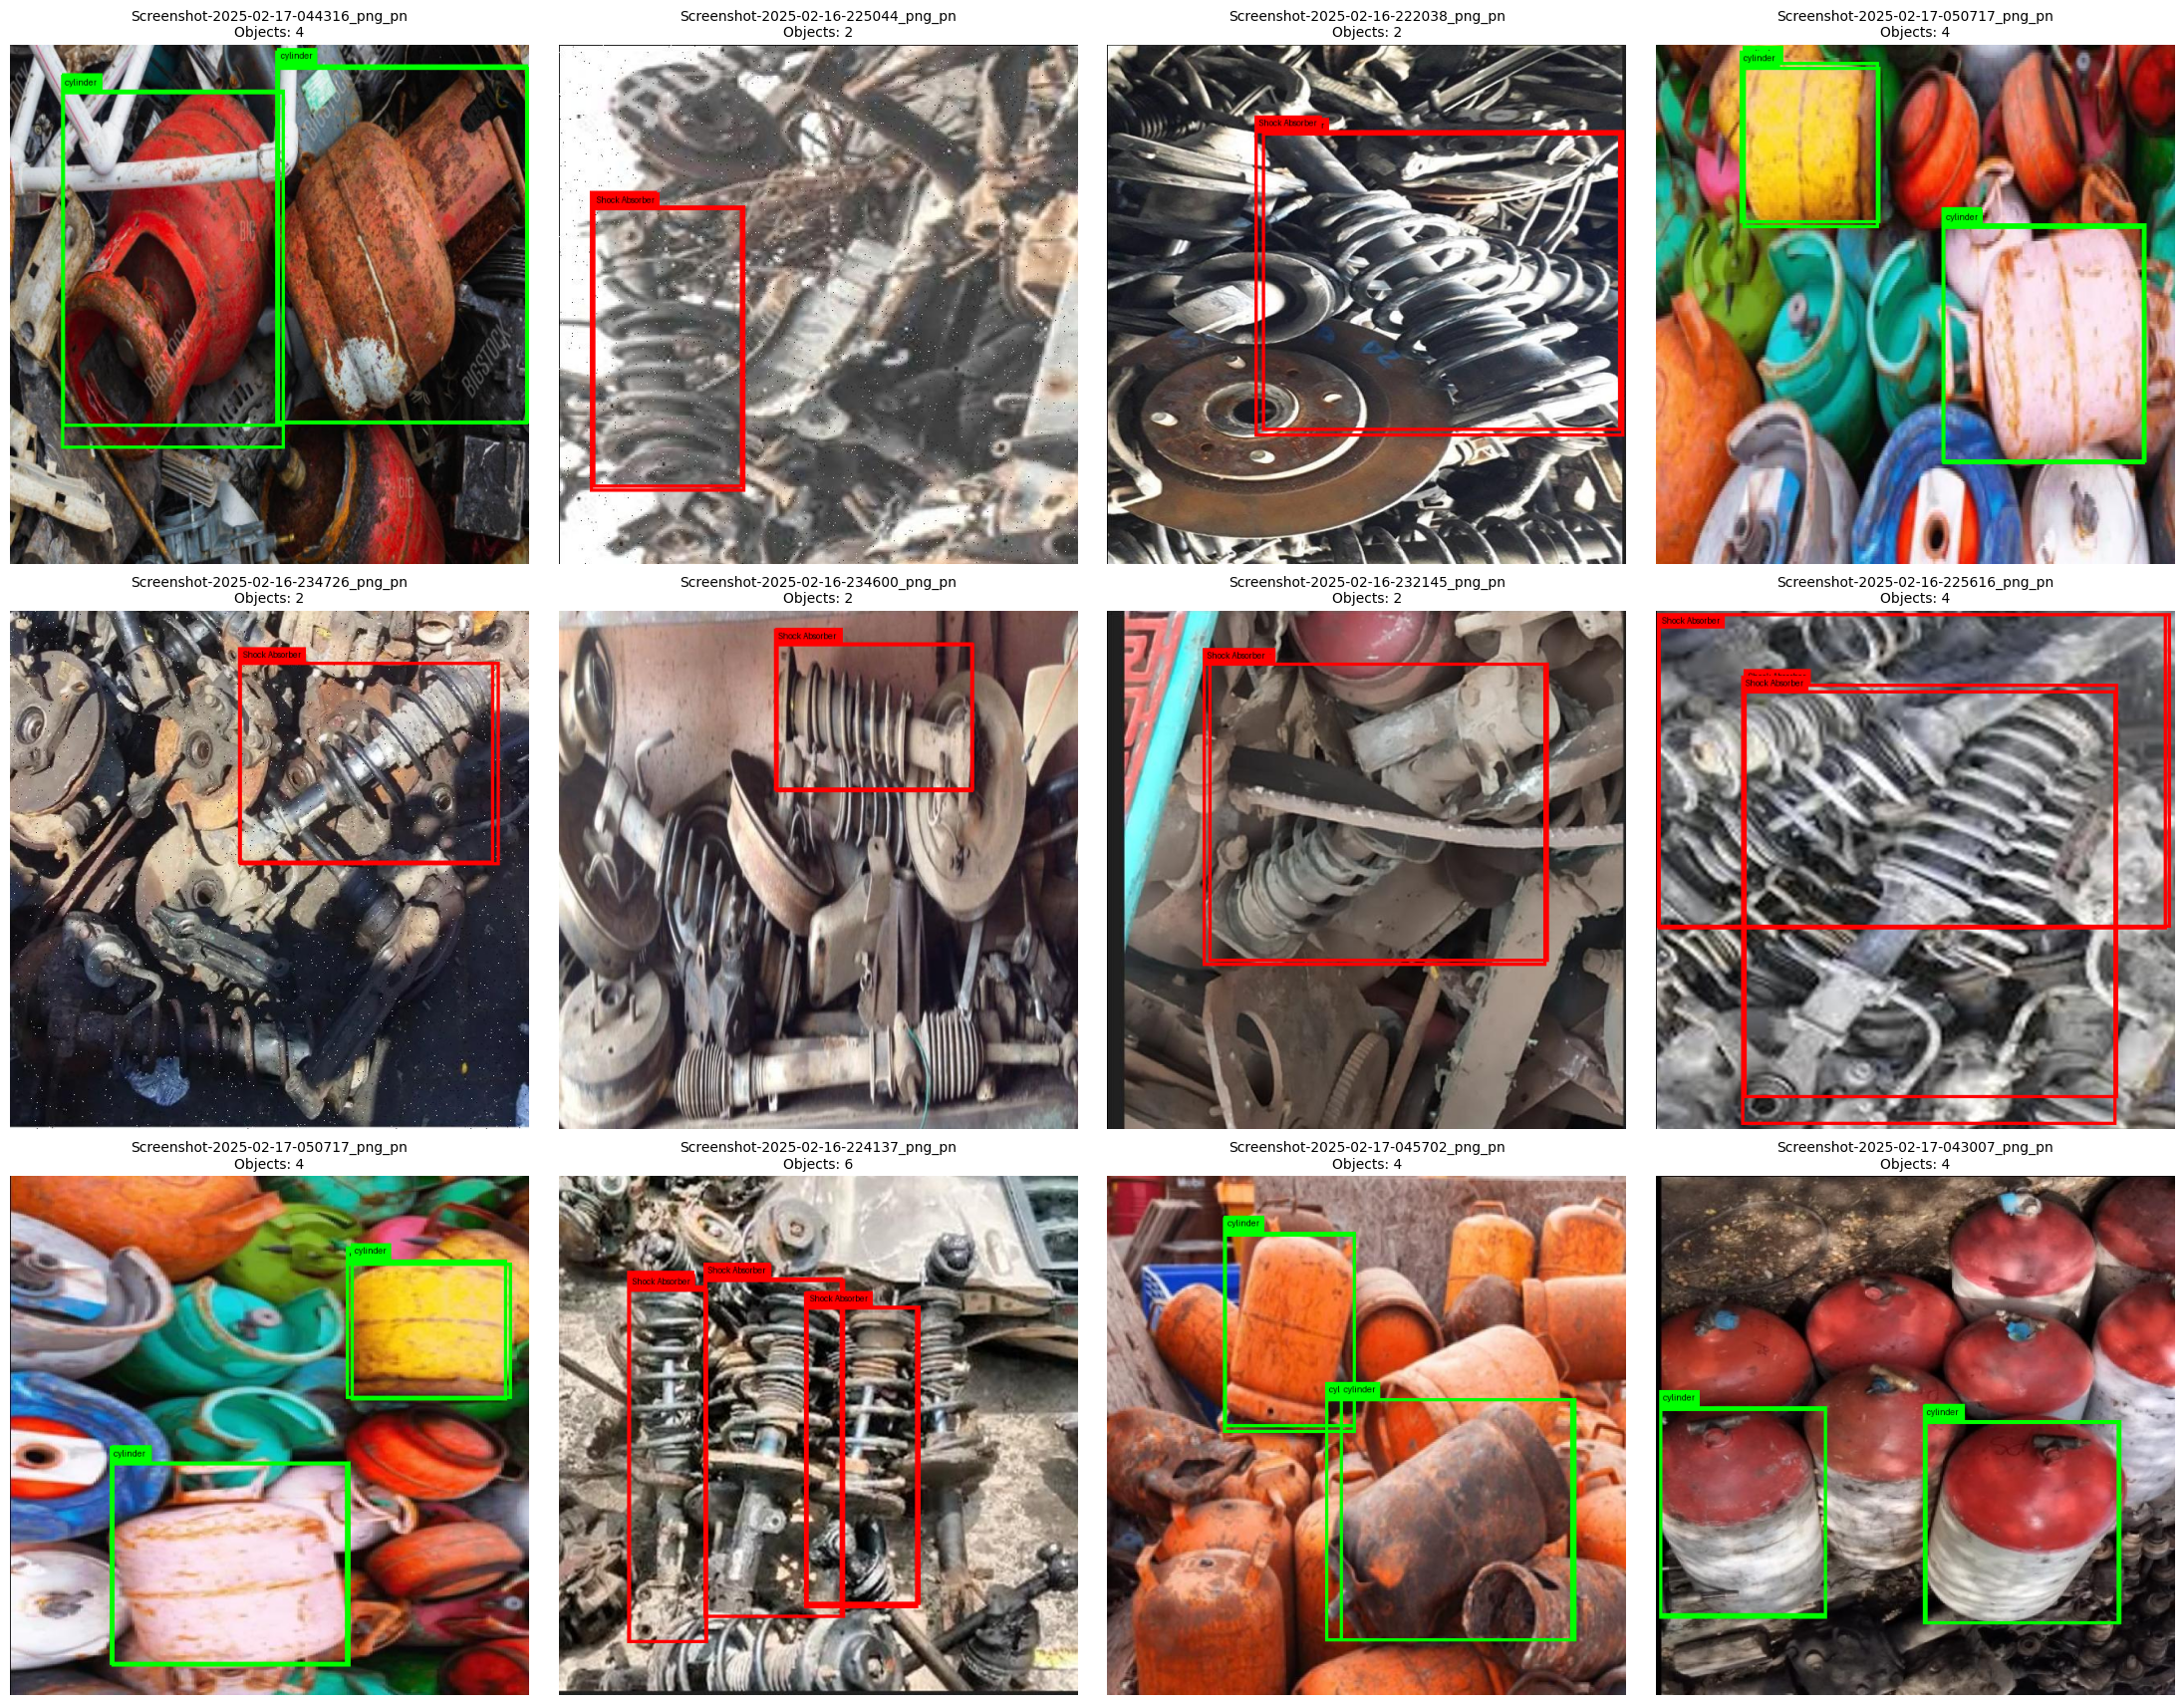

STEP 4C — VISUAL ANNOTATION REVIEW
Red: Shock Absorber
Green: Cylinder
Images displayed: 12
Review box placement, object coverage and class accuracy.


In [11]:

# STEP 4C — VISUAL ANNOTATION QUALITY CHECK
# Verify ground-truth bounding boxes and class labels.

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont, ImageOps
import matplotlib.pyplot as plt
import random

DATASET_ROOT = Path(
    "/content/datasets/original/hazwaste_v9_detection_prepared"
)

CLASS_NAMES = ["Shock Absorber", "cylinder"]
CLASS_COLORS = ["red", "lime"]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
SAMPLE_SIZE = 12
SEED = 42

images_dir = DATASET_ROOT / "train" / "images"
labels_dir = DATASET_ROOT / "train" / "labels"

images = sorted(
    p for p in images_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
)

assert images, "No training images found."

rng = random.Random(SEED)
sample_images = rng.sample(
    images, min(SAMPLE_SIZE, len(images))
)

def load_font(size=24):
    for font_path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf",
    ):
        if Path(font_path).exists():
            return ImageFont.truetype(font_path, size)

    return ImageFont.load_default()

font = load_font()

fig, axes = plt.subplots(
    3, 4,
    figsize=(22, 17),
    constrained_layout=True
)

for ax, image_path in zip(axes.flat, sample_images):

    with Image.open(image_path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")

    width, height = image.size
    draw = ImageDraw.Draw(image)

    label_path = labels_dir / f"{image_path.stem}.txt"
    assert label_path.exists(), f"Missing label: {label_path}"

    annotation_count = 0

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        values = line.split()
        assert len(values) == 5, f"Invalid label: {label_path}"

        class_id = int(values[0])
        xc, yc, bw, bh = map(float, values[1:])

        assert class_id in (0, 1), f"Unknown class: {class_id}"

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height
        x2 = (xc + bw / 2) * width
        y2 = (yc + bh / 2) * height

        color = CLASS_COLORS[class_id]
        class_name = CLASS_NAMES[class_id]

        # Draw bounding box.
        line_width = max(3, round(min(width, height) / 150))

        draw.rectangle(
            (x1, y1, x2, y2),
            outline=color,
            width=line_width
        )

        # Draw a readable label with a filled background.
        text_bbox = draw.textbbox(
            (0, 0), class_name, font=font
        )

        text_width = text_bbox[2] - text_bbox[0]
        text_height = text_bbox[3] - text_bbox[1]

        padding = 5
        label_width = text_width + 2 * padding
        label_height = text_height + 2 * padding

        label_x = max(0, min(int(x1), width - label_width))
        label_y = (
            int(y1) - label_height
            if y1 >= label_height
            else int(y1)
        )
        label_y = max(0, min(label_y, height - label_height))

        draw.rectangle(
            (
                label_x,
                label_y,
                label_x + label_width,
                label_y + label_height
            ),
            fill=color
        )

        draw.text(
            (
                label_x + padding,
                label_y + padding - text_bbox[1]
            ),
            class_name,
            fill="black",
            font=font
        )

        annotation_count += 1

    ax.imshow(image)
    ax.set_title(
        f"{image_path.name[:35]}\n"
        f"Objects: {annotation_count}",
        fontsize=10
    )
    ax.axis("off")

for ax in list(axes.flat)[len(sample_images):]:
    ax.axis("off")

plt.show()

print("STEP 4C — VISUAL ANNOTATION REVIEW")
print("Red: Shock Absorber")
print("Green: Cylinder")
print(f"Images displayed: {len(sample_images)}")
print("Review box placement, object coverage and class accuracy.")


Step 5 — Model Building:

What this does
- Downloads and initializes YOLOv8n, YOLOv8s and YOLO26n.
- Verifies that all three are object-detection models.
- Displays their architectures and parameter counts.
- Establishes the two target classes for our project.

Three YOLO models were pretrained on the COCO dataset, which contains 80 object classes, including people, cars, dogs and bicycles.

0 gradients in the model summary does not mean training is disabled. It indicates gradients are not currently being tracked for those parameters. Training will enable the required gradients.

Metric	Meaning	Your model
260 layers:
The number of layers/modules reported by Ultralytics, which process and transform image features	260

2,572,280 parameters:
The model's learnable weights and biases, adjusted during training	~2.57 million

0 gradients:
No parameter gradients are currently being reported in this summary	0

6.2 GFLOPs:
Approximately 6.2 billion floating-point operations for one forward pass at the model's profiling input size

In [12]:

# STEP 5 — MODEL BUILDING

%pip install -q -U ultralytics

import torch
import ultralytics
from ultralytics import YOLO

MODEL_WEIGHTS = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv8s": "yolov8s.pt",
    "YOLO26n": "yolo26n.pt",
}

CLASS_NAMES = ["Shock Absorber", "cylinder"]
models = {}

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

for name, weights in MODEL_WEIGHTS.items():
    print(f"\n{'=' * 55}")
    print(f"BUILDING: {name}")

    model = YOLO(weights)

    assert model.task == "detect", (
        f"{name}: Expected object detection, got {model.task}"
    )

    models[name] = model

    print("Architecture:", type(model.model).__name__)
    print("Task:", model.task)
    print("Pretrained classes:", len(model.names))
    print(
        "Parameters:",
        f"{sum(p.numel() for p in model.model.parameters()):,}"
    )

    # Inspect architecture, including detection head.
    model.info(detailed=False)

print("\nAll three pretrained detection models initialized.")
print("Target classes:", CLASS_NAMES)
print("Target class count:", len(CLASS_NAMES))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.189
PyTorch: 2.11.0+cu130
GPU available: True

BUILDING: YOLOv8n
Architecture: DetectionModel
Task: detect
Pretrained classes: 80
Parameters: 3,157,200
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs

BUILDING: YOLOv8s
Architecture: DetectionModel
Task: detect
Pretrained classes: 80
Parameters: 11,166,560
YOLOv8s summary: 129 layers, 11,166,560 parameters, 0 gradients, 28.8 GFLOPs

BUILDING: YOLO26n
Architecture: DetectionModel
Task: detect
Pretrained classes: 80
Parameters: 2,572,280
YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs

All three pretrained detection models initialized.
Target classes: ['Shock Absorber', 'cylinder']

Step 6 — Model Training (Train YOLOv8n on the Original Dataset)

In [13]:

# STEP 6A — TRAIN YOLOv8n ON ORIGINAL DATASET

from pathlib import Path
from ultralytics import YOLO
import torch
import random
import numpy as np
import pandas as pd
import time
import json

SEED = 42
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "GPU required for training."

DATASET_ROOT = Path(
    "/content/datasets/original/hazwaste_v9_detection_prepared"
)
DATA_YAML = DATASET_ROOT / "data.yaml"

assert DATA_YAML.is_file(), "Dataset configuration not found."

# Use an absolute-path dataset configuration for Colab.
import yaml

with open(DATA_YAML) as f:
    data_config = yaml.safe_load(f)

assert data_config["names"] == ["Shock Absorber", "cylinder"]
assert data_config["nc"] == 2

data_config["path"] = str(DATASET_ROOT.resolve())
data_config["train"] = "train/images"
data_config["val"] = "valid/images"
data_config["test"] = "test/images"

TRAINING_YAML = DATASET_ROOT / "data_colab.yaml"

with open(TRAINING_YAML, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# Fresh pretrained checkpoint for this experiment.
model = YOLO("yolov8n.pt")

start_time = time.perf_counter()

results = model.train(
    data=str(TRAINING_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    deterministic=True,
    device=0,
    workers=2,
    pretrained=True,
    patience=15,
    project="/content/yolo_experiments",
    name="yolov8n_original",
    exist_ok=False,
    plots=True,
    save=True,
    verbose=True,
)

training_seconds = time.perf_counter() - start_time

run_dir = Path(model.trainer.save_dir)
history_path = run_dir / "results.csv"
best_checkpoint = run_dir / "weights" / "best.pt"

assert history_path.exists(), "Training history was not saved."
assert best_checkpoint.exists(), "Best checkpoint was not saved."

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

summary = {
    "experiment": "yolov8n_original",
    "architecture": "YOLOv8n",
    "dataset": "original",
    "seed": SEED,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "training_seconds": round(training_seconds, 2),
    "gpu": torch.cuda.get_device_name(0),
    "best_checkpoint": str(best_checkpoint),
    "training_history": str(history_path),
}

with open(run_dir / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nTRAINING COMPLETED")
print(json.dumps(summary, indent=2))

print("\nTraining metrics:")
print(history.tail(5).to_string(index=False))


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/original/hazwaste_v9_detection_prepared/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_origina

Step 6B: Preserve training artifacts

In [15]:

# STEP 6B — BACK UP FIRST TRAINING EXPERIMENT

from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

source = Path("/content/yolo_experiments/yolov8n_original")
destination = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/"
    "experiments/yolov8n_original"
)

assert source.is_dir(), "Training experiment folder not found."
assert (source / "weights/best.pt").is_file()
assert (source / "results.csv").is_file()

destination.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(source, destination, dirs_exist_ok=True)

assert (destination / "weights/best.pt").is_file()
assert (destination / "results.csv").is_file()

print("Backup completed:", destination)
print("Best model:", destination / "weights/best.pt")
print("Training history:", destination / "results.csv")


Mounted at /content/drive
Backup completed: /content/drive/MyDrive/HazWaste_YOLO_Project/experiments/yolov8n_original
Best model: /content/drive/MyDrive/HazWaste_YOLO_Project/experiments/yolov8n_original/weights/best.pt
Training history: /content/drive/MyDrive/HazWaste_YOLO_Project/experiments/yolov8n_original/results.csv


Step 6C — Train YOLOv8s on the Original Dataset

In [16]:

# STEP 6C — TRAIN YOLOv8s ON ORIGINAL DATASET

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json
import time
import shutil

experiment_name = "yolov8s_original"

# Initialize a fresh pretrained YOLOv8s model.
model = YOLO("yolov8s.pt")

start_time = time.perf_counter()

results = model.train(
    data=str(TRAINING_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    deterministic=True,
    device=0,
    workers=2,
    pretrained=True,
    patience=15,
    project="/content/yolo_experiments",
    name=experiment_name,
    exist_ok=False,
    plots=True,
    save=True,
    verbose=True,
)

training_seconds = time.perf_counter() - start_time

run_dir = Path(model.trainer.save_dir)
history_path = run_dir / "results.csv"
best_checkpoint = run_dir / "weights" / "best.pt"

assert history_path.is_file()
assert best_checkpoint.is_file()

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

summary = {
    "experiment": experiment_name,
    "architecture": "YOLOv8s",
    "dataset": "original",
    "seed": SEED,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "training_seconds": round(training_seconds, 2),
    "best_checkpoint": str(best_checkpoint),
    "training_history": str(history_path),
}

with open(run_dir / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# Back up the complete experiment to Google Drive.
backup_dir = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/"
    "experiments"
) / experiment_name

backup_dir.parent.mkdir(parents=True, exist_ok=True)

shutil.copytree(run_dir, backup_dir, dirs_exist_ok=True)

assert (backup_dir / "weights/best.pt").is_file()
assert (backup_dir / "results.csv").is_file()

print("\nTRAINING AND BACKUP COMPLETED")
print(json.dumps(summary, indent=2))
print("\nFinal five epochs:")
print(history.tail(5).to_string(index=False))
print("\nGoogle Drive backup:", backup_dir)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/original/hazwaste_v9_detection_prepared/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_origina

Step 6D — Train YOLO26n on the Original Dataset

In [17]:

# STEP 6D — TRAIN YOLO26n ON ORIGINAL DATASET

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json
import time
import shutil

experiment_name = "yolo26n_original"

# Start from a fresh pretrained checkpoint.
model = YOLO("yolo26n.pt")

start_time = time.perf_counter()

results = model.train(
    data=str(TRAINING_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    deterministic=True,
    device=0,
    workers=2,
    pretrained=True,
    patience=15,
    project="/content/yolo_experiments",
    name=experiment_name,
    exist_ok=False,
    plots=True,
    save=True,
    verbose=True,
)

training_seconds = time.perf_counter() - start_time

run_dir = Path(model.trainer.save_dir)
history_path = run_dir / "results.csv"
best_checkpoint = run_dir / "weights" / "best.pt"

assert history_path.is_file()
assert best_checkpoint.is_file()

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

summary = {
    "experiment": experiment_name,
    "architecture": "YOLO26n",
    "dataset": "original",
    "seed": SEED,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "training_seconds": round(training_seconds, 2),
    "best_checkpoint": str(best_checkpoint),
    "training_history": str(history_path),
}

with open(run_dir / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# Back up the experiment to Google Drive.
backup_dir = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/"
    "experiments"
) / experiment_name

backup_dir.parent.mkdir(parents=True, exist_ok=True)
shutil.copytree(run_dir, backup_dir, dirs_exist_ok=True)

assert (backup_dir / "weights/best.pt").is_file()
assert (backup_dir / "results.csv").is_file()

print("\nTRAINING AND BACKUP COMPLETED")
print(json.dumps(summary, indent=2))
print("\nFinal five epochs:")
print(history.tail(5).to_string(index=False))
print("\nGoogle Drive backup:", backup_dir)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/original/hazwaste_v9_detection_prepared/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_origina

Step 6E — Compare all three models


ORIGINAL DATASET — MODEL COMPARISON

  Model  Best Epoch  Precision  Recall     F1  mAP50  mAP50-95  Training Time (s)
YOLO26n          48     0.5754  0.4768 0.5215 0.5237    0.3534             210.75
YOLOv8n          50     0.6790  0.4905 0.5695 0.5222    0.3255             180.95
YOLOv8s          49     0.7969  0.3693 0.5047 0.4962    0.3159             220.12


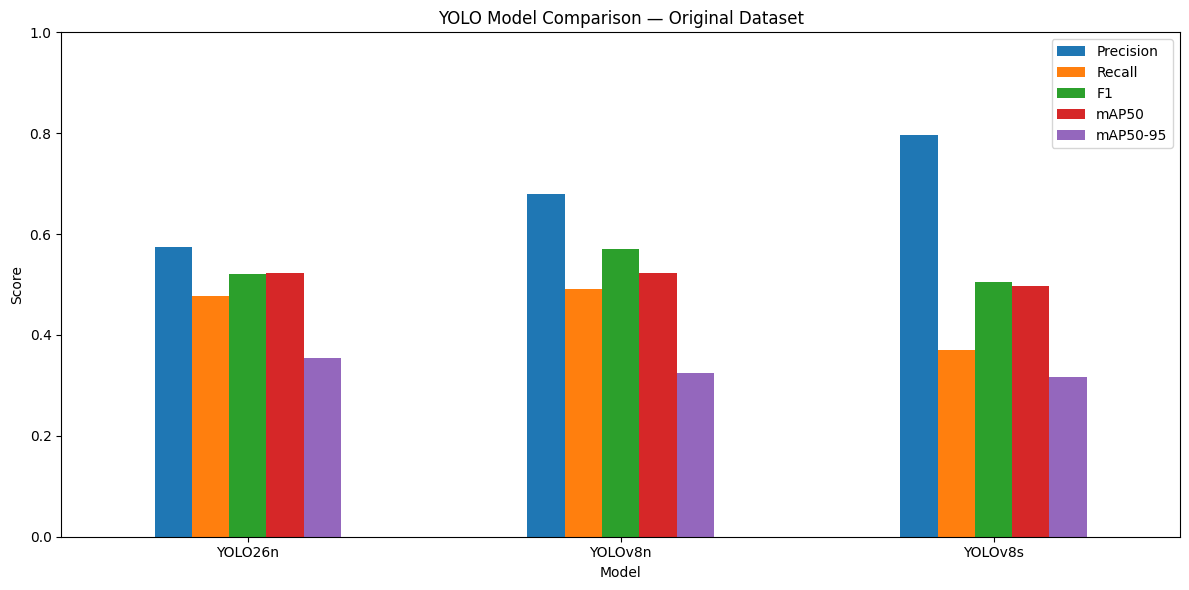


Best model by validation mAP50-95:
YOLO26n

Saved comparison: /content/drive/MyDrive/HazWaste_YOLO_Project/comparisons/original_models_comparison.csv
Saved chart: /content/drive/MyDrive/HazWaste_YOLO_Project/comparisons/original_models_comparison.png


In [18]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

BASE = Path("/content/drive/MyDrive/HazWaste_YOLO_Project/experiments")

EXPERIMENTS = {
    "YOLOv8n": "yolov8n_original",
    "YOLOv8s": "yolov8s_original",
    "YOLO26n": "yolo26n_original",
}

records = []

for model_name, experiment in EXPERIMENTS.items():
    folder = BASE / experiment

    history = pd.read_csv(folder / "results.csv")
    history.columns = history.columns.str.strip()

    with open(folder / "experiment_summary.json") as f:
        summary = json.load(f)

    # Select the epoch with the highest validation mAP50-95.
    best_idx = history["metrics/mAP50-95(B)"].idxmax()
    best = history.loc[best_idx]

    precision = float(best["metrics/precision(B)"])
    recall = float(best["metrics/recall(B)"])

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    records.append({
        "Model": model_name,
        "Best Epoch": int(best["epoch"]),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "mAP50": float(best["metrics/mAP50(B)"]),
        "mAP50-95": float(best["metrics/mAP50-95(B)"]),
        "Training Time (s)": summary["training_seconds"],
    })

comparison = pd.DataFrame(records)
comparison = comparison.sort_values(
    "mAP50-95", ascending=False
).reset_index(drop=True)

print("\nORIGINAL DATASET — MODEL COMPARISON\n")
print(comparison.round(4).to_string(index=False))

# Plot validation metrics.
metrics = ["Precision", "Recall", "F1", "mAP50", "mAP50-95"]

ax = comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

ax.set_title("YOLO Model Comparison — Original Dataset")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="upper right")

plt.tight_layout()

output_dir = BASE.parent / "comparisons"
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "original_models_comparison.csv"
chart_path = output_dir / "original_models_comparison.png"

comparison.to_csv(csv_path, index=False)
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nBest model by validation mAP50-95:")
print(comparison.iloc[0]["Model"])

print("\nSaved comparison:", csv_path)
print("Saved chart:", chart_path)


Key findings
- YOLO26n: Best mAP50-95 at 35.34%, indicating the strongest overall bounding-box detection performance under this metric.
- YOLOv8n: Best recall (49.05%) and F1 (56.95%) among the three at their selected epochs.
- YOLOv8s: Highest precision (79.69%), but lowest recall (36.93%). It is more selective in its detections at the reported operating point.

Step 7: Balanced Dataset Training:
Configure and verify the balanced dataset's data.yaml, ensuring it points to the correct training, validation and test directories before training.

In [19]:

# STEP 7A — VALIDATE BALANCED DATASET CONFIGURATION

from pathlib import Path
import yaml

BALANCED_ROOT = Path("/content/datasets/balanced")
BALANCED_YAML = BALANCED_ROOT / "data.yaml"

assert BALANCED_YAML.is_file(), "Balanced data.yaml not found"

with open(BALANCED_YAML) as f:
    config = yaml.safe_load(f)

print("Existing configuration:")
print(config)

assert config["names"] == ["Shock Absorber", "cylinder"]
assert config["nc"] == 2

for split in ["train", "valid", "test"]:
    image_dir = BALANCED_ROOT / split / "images"
    label_dir = BALANCED_ROOT / split / "labels"

    assert image_dir.is_dir(), f"Missing: {image_dir}"
    assert label_dir.is_dir(), f"Missing: {label_dir}"

    print(
        f"{split}: "
        f"{len(list(image_dir.glob('*')))} image files, "
        f"{len(list(label_dir.glob('*.txt')))} label files"
    )

config["path"] = str(BALANCED_ROOT.resolve())
config["train"] = "train/images"
config["val"] = "valid/images"
config["test"] = "test/images"

BALANCED_TRAINING_YAML = BALANCED_ROOT / "data_colab.yaml"

with open(BALANCED_TRAINING_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("\nBalanced dataset configuration ready:")
print(BALANCED_TRAINING_YAML)


Existing configuration:
{'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 2, 'names': ['Shock Absorber', 'cylinder']}
train: 274 image files, 274 label files
valid: 32 image files, 32 label files
test: 14 image files, 14 label files

Balanced dataset configuration ready:
/content/datasets/balanced/data_colab.yaml


7B — Train YOLOv8n on Balanced Dataset

In [20]:

# STEP 7B — TRAIN YOLOv8n ON BALANCED DATASET

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json
import time
import shutil

experiment_name = "yolov8n_balanced"

model = YOLO("yolov8n.pt")

start_time = time.perf_counter()

model.train(
    data=str(BALANCED_TRAINING_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    deterministic=True,
    device=0,
    workers=2,
    pretrained=True,
    patience=15,
    project="/content/yolo_experiments",
    name=experiment_name,
    exist_ok=False,
    plots=True,
    save=True,
    verbose=True,
)

training_seconds = time.perf_counter() - start_time

run_dir = Path(model.trainer.save_dir)
history_path = run_dir / "results.csv"
best_checkpoint = run_dir / "weights" / "best.pt"

assert history_path.is_file()
assert best_checkpoint.is_file()

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

summary = {
    "experiment": experiment_name,
    "architecture": "YOLOv8n",
    "dataset": "balanced",
    "seed": SEED,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "training_seconds": round(training_seconds, 2),
    "best_checkpoint": str(best_checkpoint),
    "training_history": str(history_path),
}

with open(run_dir / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

backup_dir = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/experiments"
) / experiment_name

backup_dir.parent.mkdir(parents=True, exist_ok=True)
shutil.copytree(run_dir, backup_dir, dirs_exist_ok=True)

assert (backup_dir / "weights/best.pt").is_file()
assert (backup_dir / "results.csv").is_file()

print("\nTRAINING AND BACKUP COMPLETED")
print(json.dumps(summary, indent=2))
print("\nFinal five epochs:")
print(history.tail(5).to_string(index=False))
print("\nGoogle Drive backup:", backup_dir)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/balanced/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_balanced, nbs=64, nms=None, opset=None

Step 7C — Train YOLOv8s on the Balanced Dataset

In [21]:

# STEP 7C — TRAIN YOLOv8s ON BALANCED DATASET

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json
import time
import shutil

experiment_name = "yolov8s_balanced"

model = YOLO("yolov8s.pt")

start_time = time.perf_counter()

model.train(
    data=str(BALANCED_TRAINING_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    deterministic=True,
    device=0,
    workers=2,
    pretrained=True,
    patience=15,
    project="/content/yolo_experiments",
    name=experiment_name,
    exist_ok=False,
    plots=True,
    save=True,
    verbose=True,
)

training_seconds = time.perf_counter() - start_time

run_dir = Path(model.trainer.save_dir)
history_path = run_dir / "results.csv"
best_checkpoint = run_dir / "weights" / "best.pt"

assert history_path.is_file()
assert best_checkpoint.is_file()

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

summary = {
    "experiment": experiment_name,
    "architecture": "YOLOv8s",
    "dataset": "balanced",
    "seed": SEED,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "training_seconds": round(training_seconds, 2),
    "best_checkpoint": str(best_checkpoint),
    "training_history": str(history_path),
}

with open(run_dir / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

backup_dir = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/experiments"
) / experiment_name

backup_dir.parent.mkdir(parents=True, exist_ok=True)
shutil.copytree(run_dir, backup_dir, dirs_exist_ok=True)

assert (backup_dir / "weights/best.pt").is_file()
assert (backup_dir / "results.csv").is_file()

print("\nTRAINING AND BACKUP COMPLETED")
print(json.dumps(summary, indent=2))
print("\nFinal five epochs:")
print(history.tail(5).to_string(index=False))
print("\nGoogle Drive backup:", backup_dir)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/balanced/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_balanced, nbs=64, nms=None, opset=None

Step 7D — Train YOLO26n on the Balanced Dataset

In [22]:

# STEP 7D — TRAIN YOLO26n ON BALANCED DATASET

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json
import time
import shutil

experiment_name = "yolo26n_balanced"

# Initialize a fresh pretrained model.
model = YOLO("yolo26n.pt")

start_time = time.perf_counter()

model.train(
    data=str(BALANCED_TRAINING_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    deterministic=True,
    device=0,
    workers=2,
    pretrained=True,
    patience=15,
    project="/content/yolo_experiments",
    name=experiment_name,
    exist_ok=False,
    plots=True,
    save=True,
    verbose=True,
)

training_seconds = time.perf_counter() - start_time

run_dir = Path(model.trainer.save_dir)
history_path = run_dir / "results.csv"
best_checkpoint = run_dir / "weights" / "best.pt"

assert history_path.is_file()
assert best_checkpoint.is_file()

history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

summary = {
    "experiment": experiment_name,
    "architecture": "YOLO26n",
    "dataset": "balanced",
    "seed": SEED,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "training_seconds": round(training_seconds, 2),
    "best_checkpoint": str(best_checkpoint),
    "training_history": str(history_path),
}

with open(run_dir / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# Back up the complete experiment.
backup_dir = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/experiments"
) / experiment_name

backup_dir.parent.mkdir(parents=True, exist_ok=True)
shutil.copytree(run_dir, backup_dir, dirs_exist_ok=True)

assert (backup_dir / "weights/best.pt").is_file()
assert (backup_dir / "results.csv").is_file()

print("\nTRAINING AND BACKUP COMPLETED")
print(json.dumps(summary, indent=2))

print("\nFinal five epochs:")
print(history.tail(5).to_string(index=False))

print("\nGoogle Drive backup:", backup_dir)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/balanced/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_balanced, nbs=64, nms=None, opset=None

Step 8A — Compare All Six YOLO Experiments


ALL SIX MODELS — VALIDATION COMPARISON

  Model  Dataset  Best Epoch  Precision  Recall     F1  mAP50  mAP50-95  Training Time (s)
YOLO26n Original          48     0.5754  0.4768 0.5215 0.5237    0.3534             210.75
YOLO26n Balanced          50     0.7562  0.4325 0.5503 0.4918    0.3522             282.38
YOLOv8s Balanced          46     0.8277  0.4333 0.5688 0.5214    0.3446             315.81
YOLOv8n Original          50     0.6790  0.4905 0.5695 0.5222    0.3255             180.95
YOLOv8n Balanced          50     0.6518  0.4547 0.5357 0.4722    0.3196             232.30
YOLOv8s Original          49     0.7969  0.3693 0.5047 0.4962    0.3159             220.12

BALANCING IMPACT — mAP50-95

Dataset  Balanced  Original  Balanced - Original
Model                                           
YOLO26n    0.3522    0.3534              -0.0013
YOLOv8n    0.3196    0.3255              -0.0059
YOLOv8s    0.3446    0.3159               0.0287


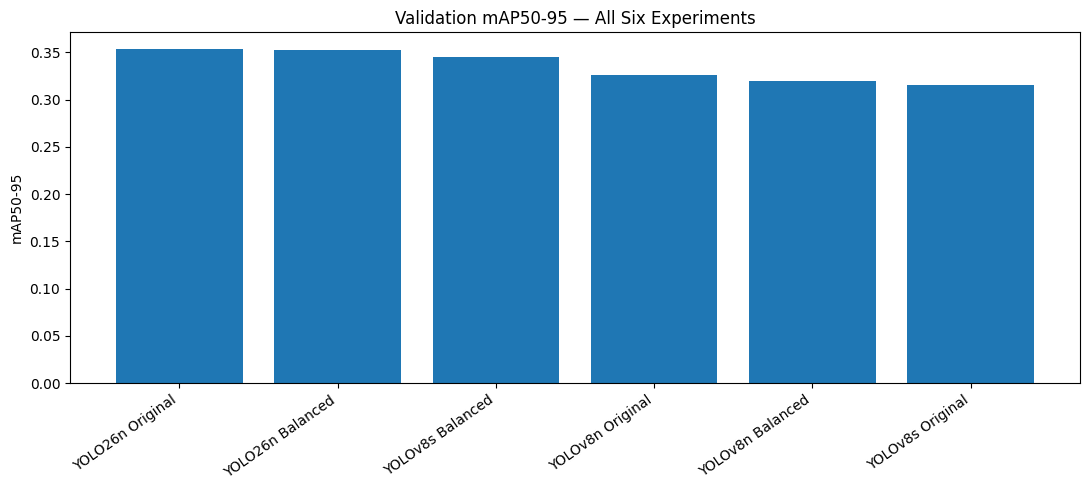

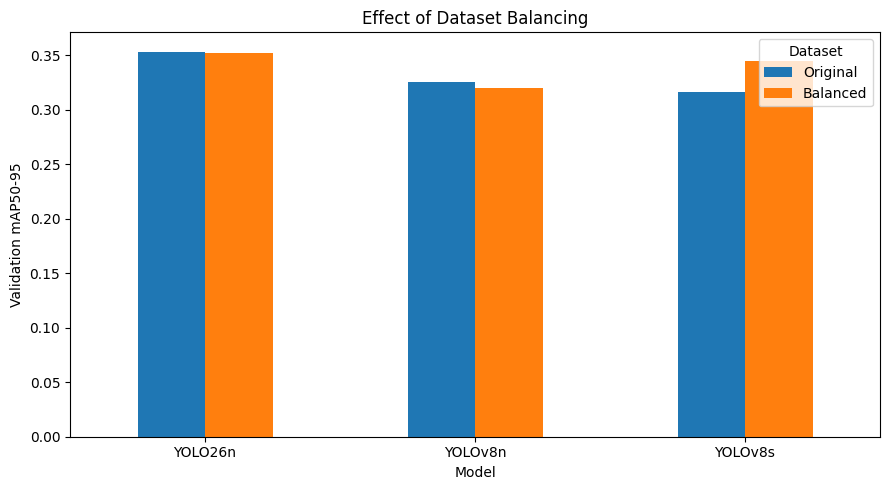


Highest validation mAP50-95:
Model        YOLO26n
Dataset     Original
mAP50-95     0.35343

Comparison artifacts saved to: /content/drive/MyDrive/HazWaste_YOLO_Project/comparisons


In [23]:

# STEP 8A — COMPARE ALL SIX YOLO EXPERIMENTS

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json

BASE = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/experiments"
)

EXPERIMENTS = {
    "yolov8n_original": ("YOLOv8n", "Original"),
    "yolov8n_balanced": ("YOLOv8n", "Balanced"),
    "yolov8s_original": ("YOLOv8s", "Original"),
    "yolov8s_balanced": ("YOLOv8s", "Balanced"),
    "yolo26n_original": ("YOLO26n", "Original"),
    "yolo26n_balanced": ("YOLO26n", "Balanced"),
}

records = []

for experiment, (architecture, dataset) in EXPERIMENTS.items():
    folder = BASE / experiment

    history_path = folder / "results.csv"
    summary_path = folder / "experiment_summary.json"
    checkpoint_path = folder / "weights" / "best.pt"

    assert history_path.is_file(), f"Missing: {history_path}"
    assert summary_path.is_file(), f"Missing: {summary_path}"
    assert checkpoint_path.is_file(), f"Missing: {checkpoint_path}"

    history = pd.read_csv(history_path)
    history.columns = history.columns.str.strip()

    with open(summary_path) as f:
        summary = json.load(f)

    best_idx = history["metrics/mAP50-95(B)"].idxmax()
    best = history.loc[best_idx]

    precision = float(best["metrics/precision(B)"])
    recall = float(best["metrics/recall(B)"])

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    records.append({
        "Model": architecture,
        "Dataset": dataset,
        "Best Epoch": int(best["epoch"]),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "mAP50": float(best["metrics/mAP50(B)"]),
        "mAP50-95": float(best["metrics/mAP50-95(B)"]),
        "Training Time (s)": float(summary["training_seconds"]),
    })

comparison = pd.DataFrame(records)
comparison = comparison.sort_values(
    "mAP50-95", ascending=False
).reset_index(drop=True)

print("\nALL SIX MODELS — VALIDATION COMPARISON\n")
print(comparison.round(4).to_string(index=False))

# Compare original versus balanced for each architecture.
pivot = comparison.pivot(
    index="Model",
    columns="Dataset",
    values="mAP50-95"
)

pivot["Balanced - Original"] = (
    pivot["Balanced"] - pivot["Original"]
)

print("\nBALANCING IMPACT — mAP50-95\n")
print(pivot.round(4).to_string())

# Save results.
OUTPUT = BASE.parent / "comparisons"
OUTPUT.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    OUTPUT / "all_six_validation_comparison.csv",
    index=False
)

pivot.to_csv(
    OUTPUT / "balancing_impact.csv"
)

# Chart 1 — Overall comparison.
labels = comparison["Model"] + " " + comparison["Dataset"]

plt.figure(figsize=(11, 5))
plt.bar(labels, comparison["mAP50-95"])
plt.title("Validation mAP50-95 — All Six Experiments")
plt.ylabel("mAP50-95")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT / "all_six_map_comparison.png", dpi=200)
plt.show()

# Chart 2 — Original vs balanced.
ax = pivot[["Original", "Balanced"]].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)
ax.set_title("Effect of Dataset Balancing")
ax.set_ylabel("Validation mAP50-95")
plt.tight_layout()
plt.savefig(OUTPUT / "balancing_impact.png", dpi=200)
plt.show()

print("\nHighest validation mAP50-95:")
print(comparison.iloc[0][
    ["Model", "Dataset", "mAP50-95"]
].to_string())

print("\nComparison artifacts saved to:", OUTPUT)


8B — Evaluate the selected model on test data
We'll now use the 14 test images, which were not used for weight updates or model selection.

In [24]:

# STEP 8B — FINAL TEST EVALUATION

from pathlib import Path
from ultralytics import YOLO
import json

project_root = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project"
)

checkpoint = (
    project_root
    / "experiments/yolo26n_original/weights/best.pt"
)

assert checkpoint.is_file(), "Best model checkpoint not found"
assert Path(TRAINING_YAML).is_file(), "Dataset YAML not found"

model = YOLO(str(checkpoint))

metrics = model.val(
    data=str(TRAINING_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/yolo_experiments",
    name="yolo26n_original_test",
    exist_ok=False,
)

results = {
    "model": "YOLO26n",
    "dataset": "Original",
    "split": "test",
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50-95": float(metrics.box.map),
    "per_class": {},
}

for class_id, class_name in model.names.items():
    results["per_class"][class_name] = {
        "mAP50-95": float(metrics.box.maps[class_id])
    }

output_dir = project_root / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "yolo26n_original_test_metrics.json"

with open(output_file, "w") as f:
    json.dump(results, f, indent=2)

print("\nFINAL TEST RESULTS")
print(json.dumps(results, indent=2))
print("\nSaved:", output_file)


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 899.8±552.7 MB/s, size: 56.1 KB)
val: Scanning /content/datasets/original/hazwaste_v9_detection_prepared/test/labels... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 480.7it/s 0.0s
val: New cache created: /content/datasets/original/hazwaste_v9_detection_prepared/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.6it/s 0.4s
                   all         14         49      0.664      0.679      0.659      0.356
        Shock Absorber          6         15      0.808        0.8       0.76      0.286
              cylinder          8         34      0.521      0.559      0.557      0.426
Speed: 0.4ms preprocess, 8.6ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved

Step 8C: Save complete test artifacts

In [25]:

from pathlib import Path
import shutil

source = Path("/content/yolo_experiments/yolo26n_original_test")

destination = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/"
    "evaluation/yolo26n_original_test_artifacts"
)

assert source.is_dir(), "Test artifacts folder not found"

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Test artifacts backed up:", destination)
print("\nSaved files:")
for file in sorted(destination.rglob("*")):
    if file.is_file():
        print(file.relative_to(destination))


Test artifacts backed up: /content/drive/MyDrive/HazWaste_YOLO_Project/evaluation/yolo26n_original_test_artifacts

Saved files:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg


8D — Inspect detection errors


confusion_matrix.png


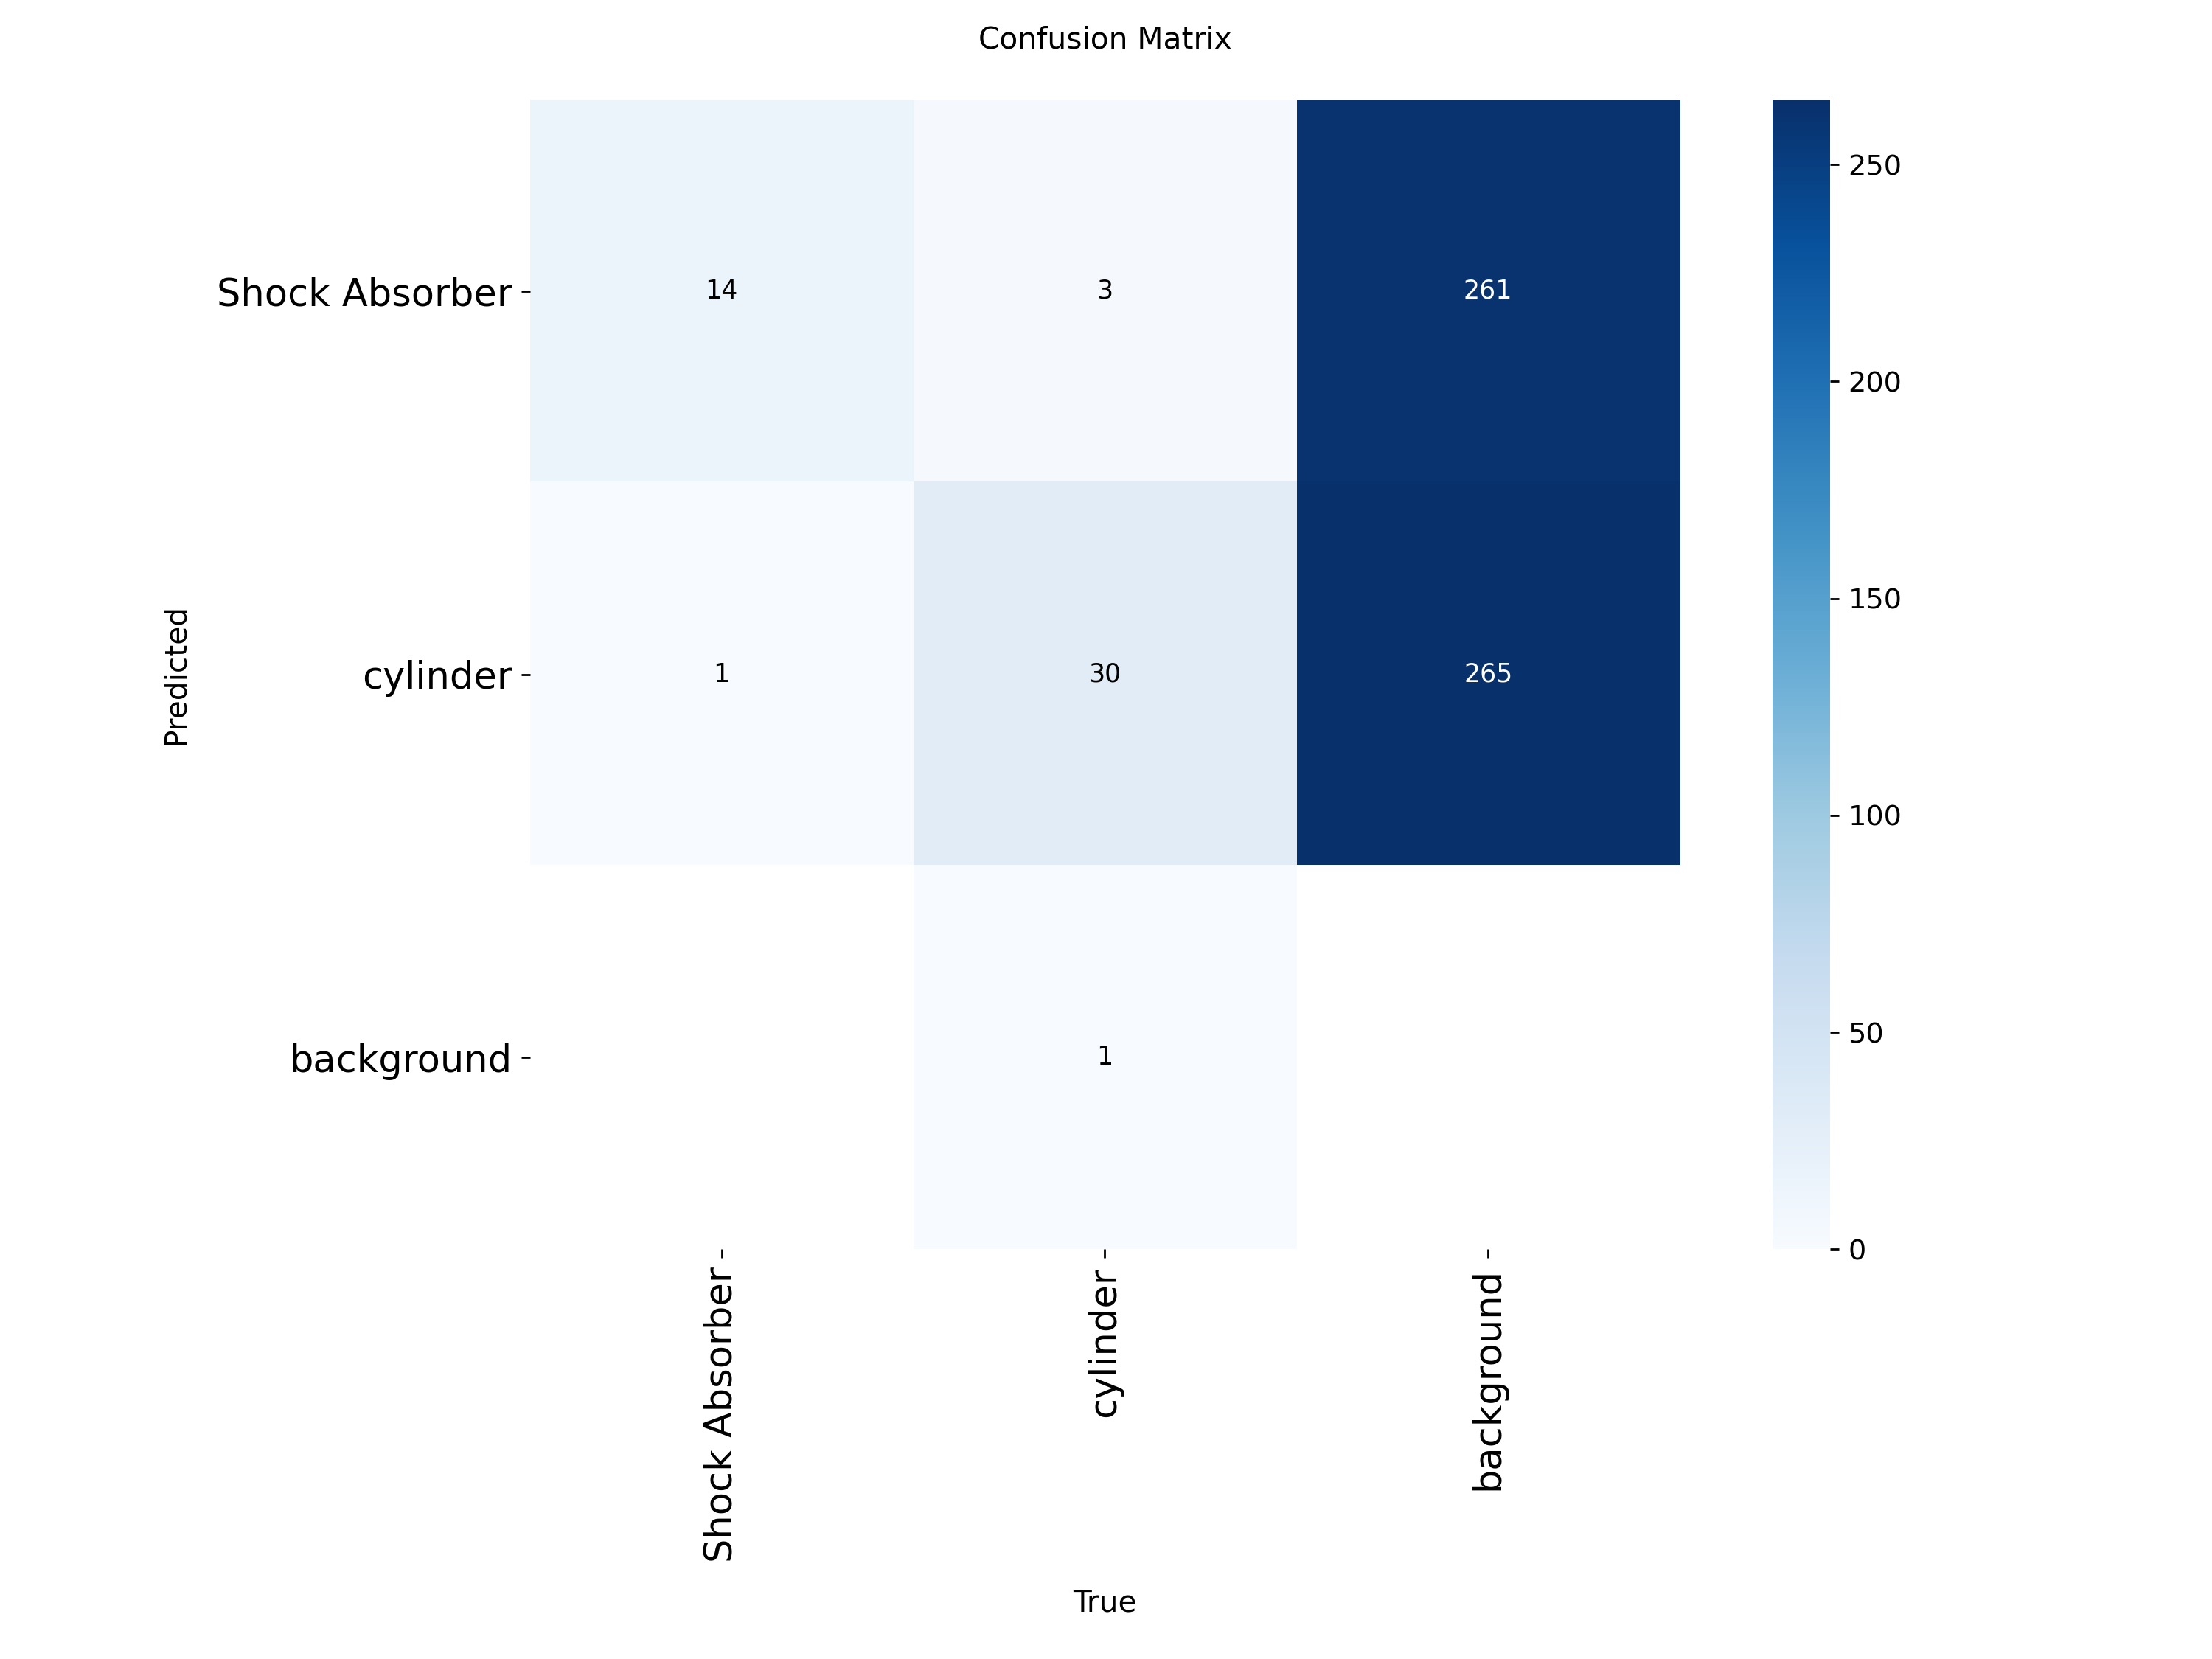


confusion_matrix_normalized.png


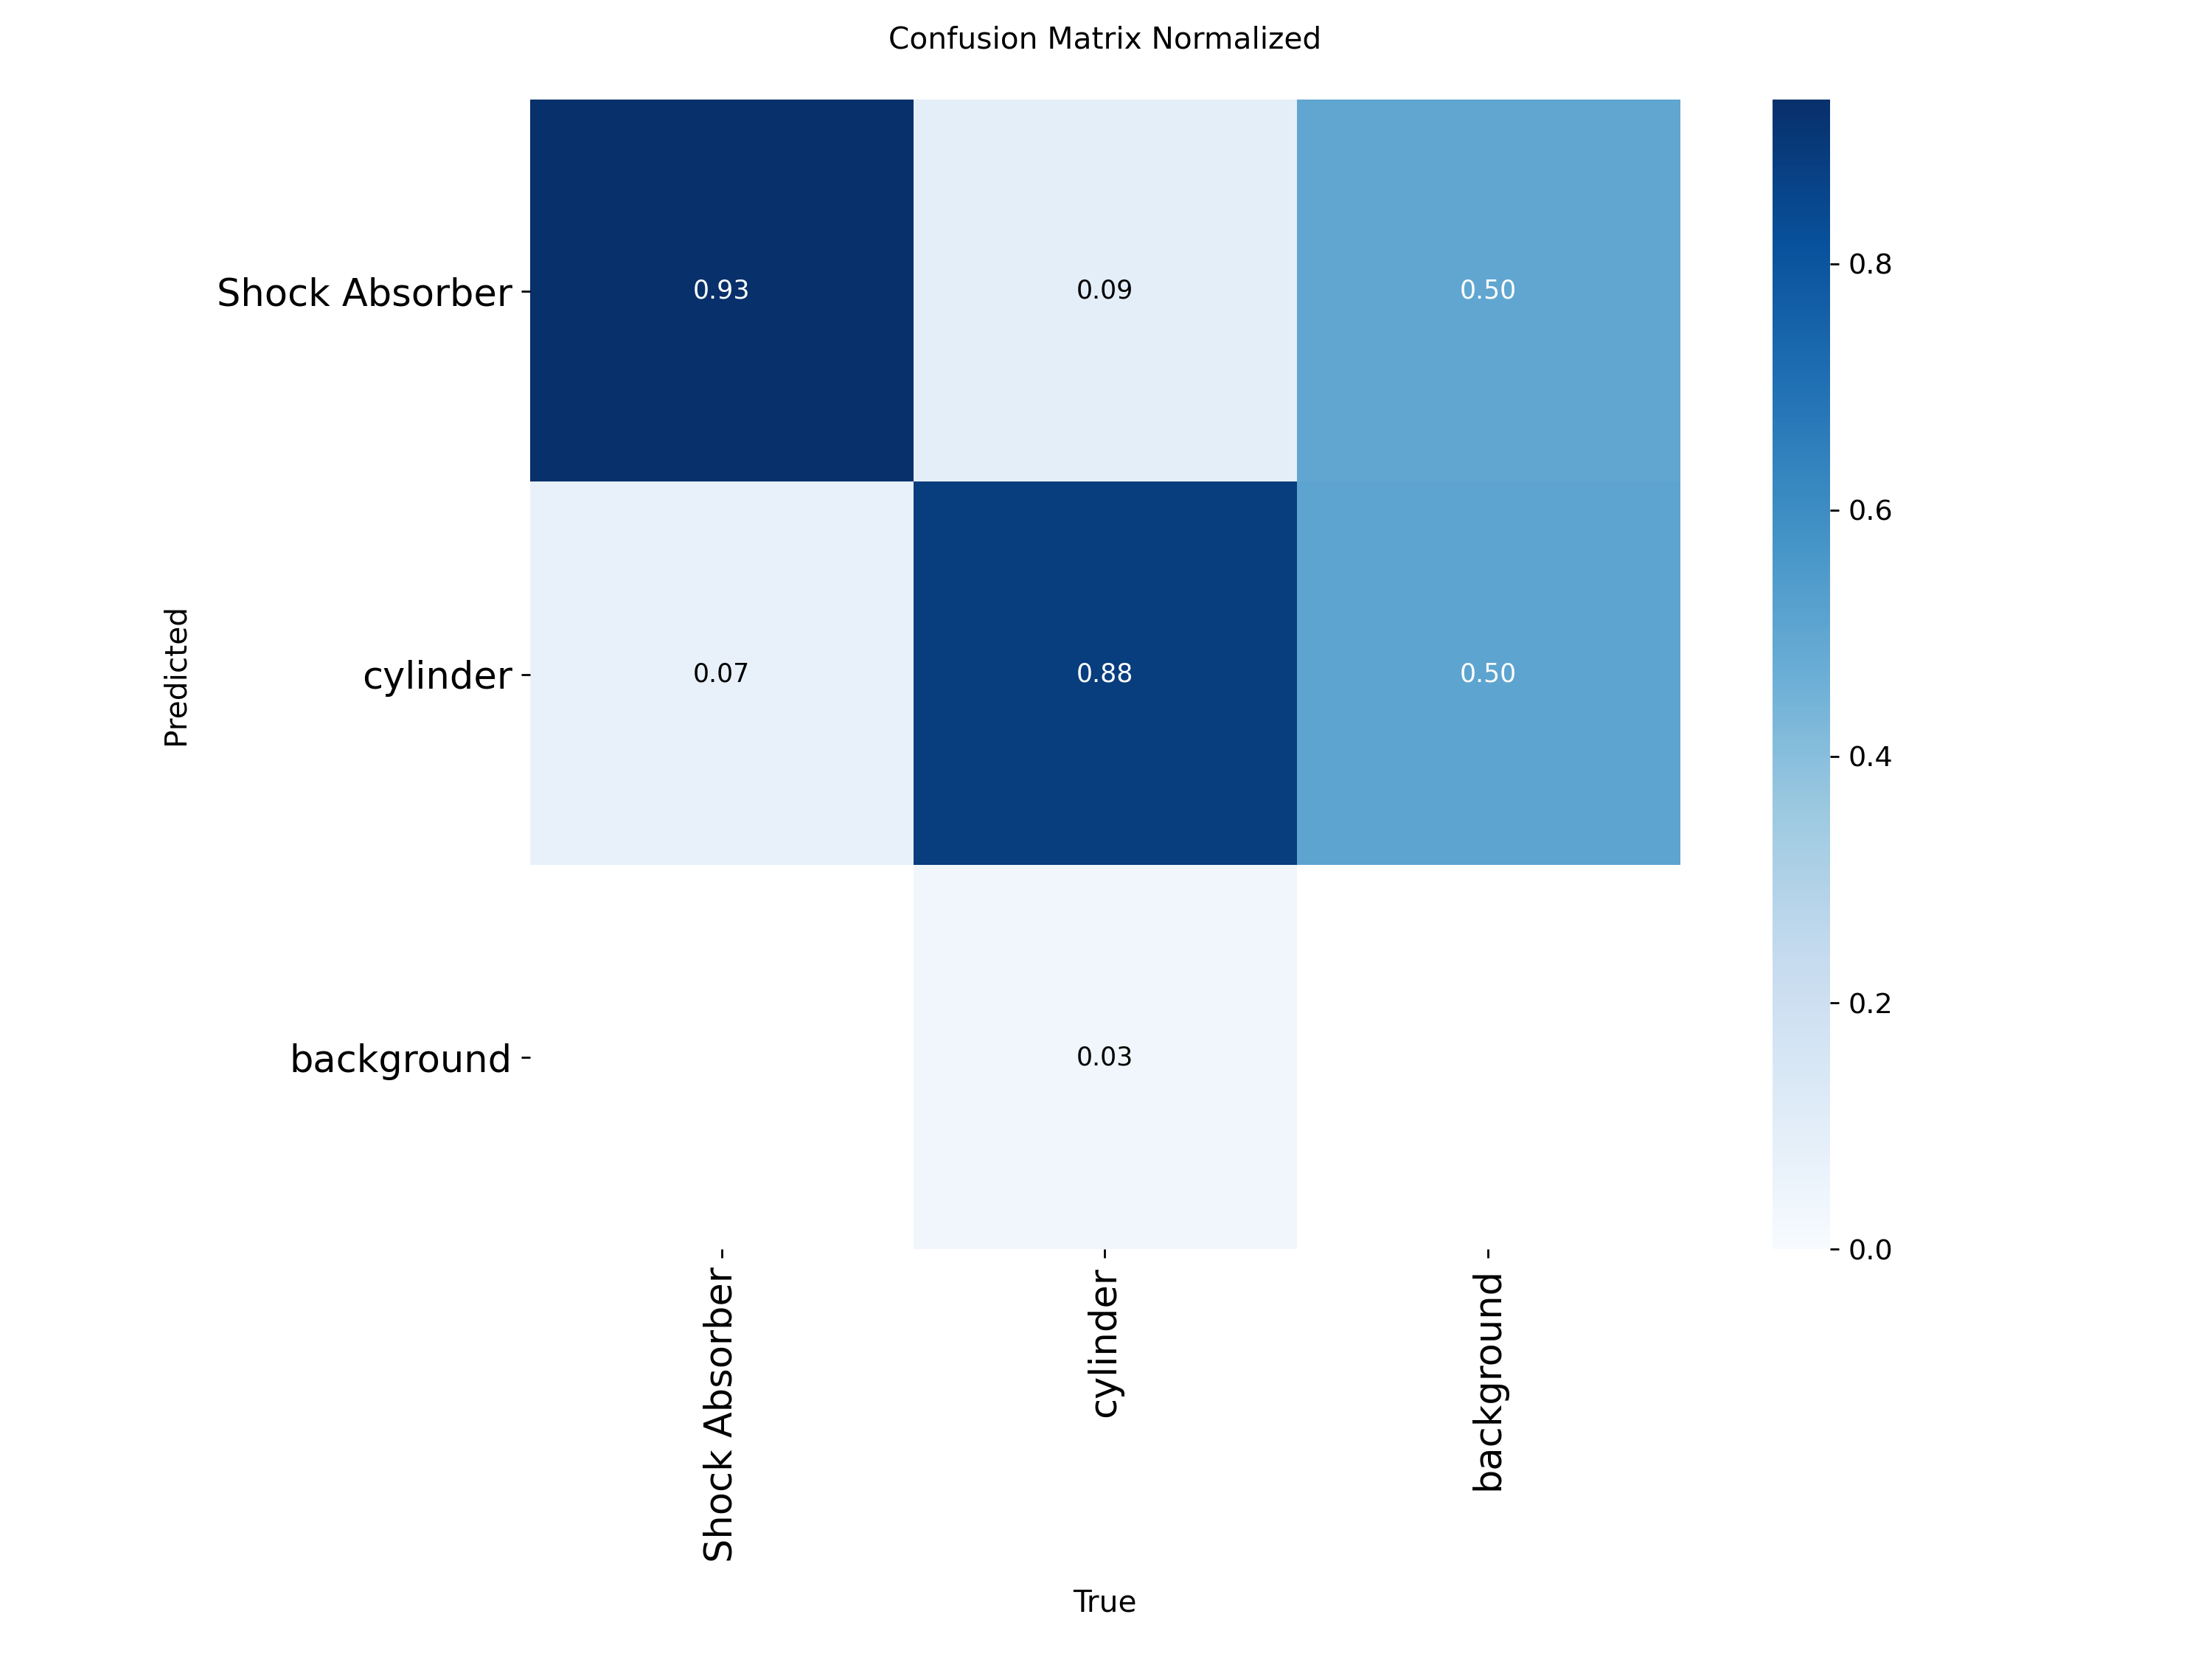


val_batch0_labels.jpg


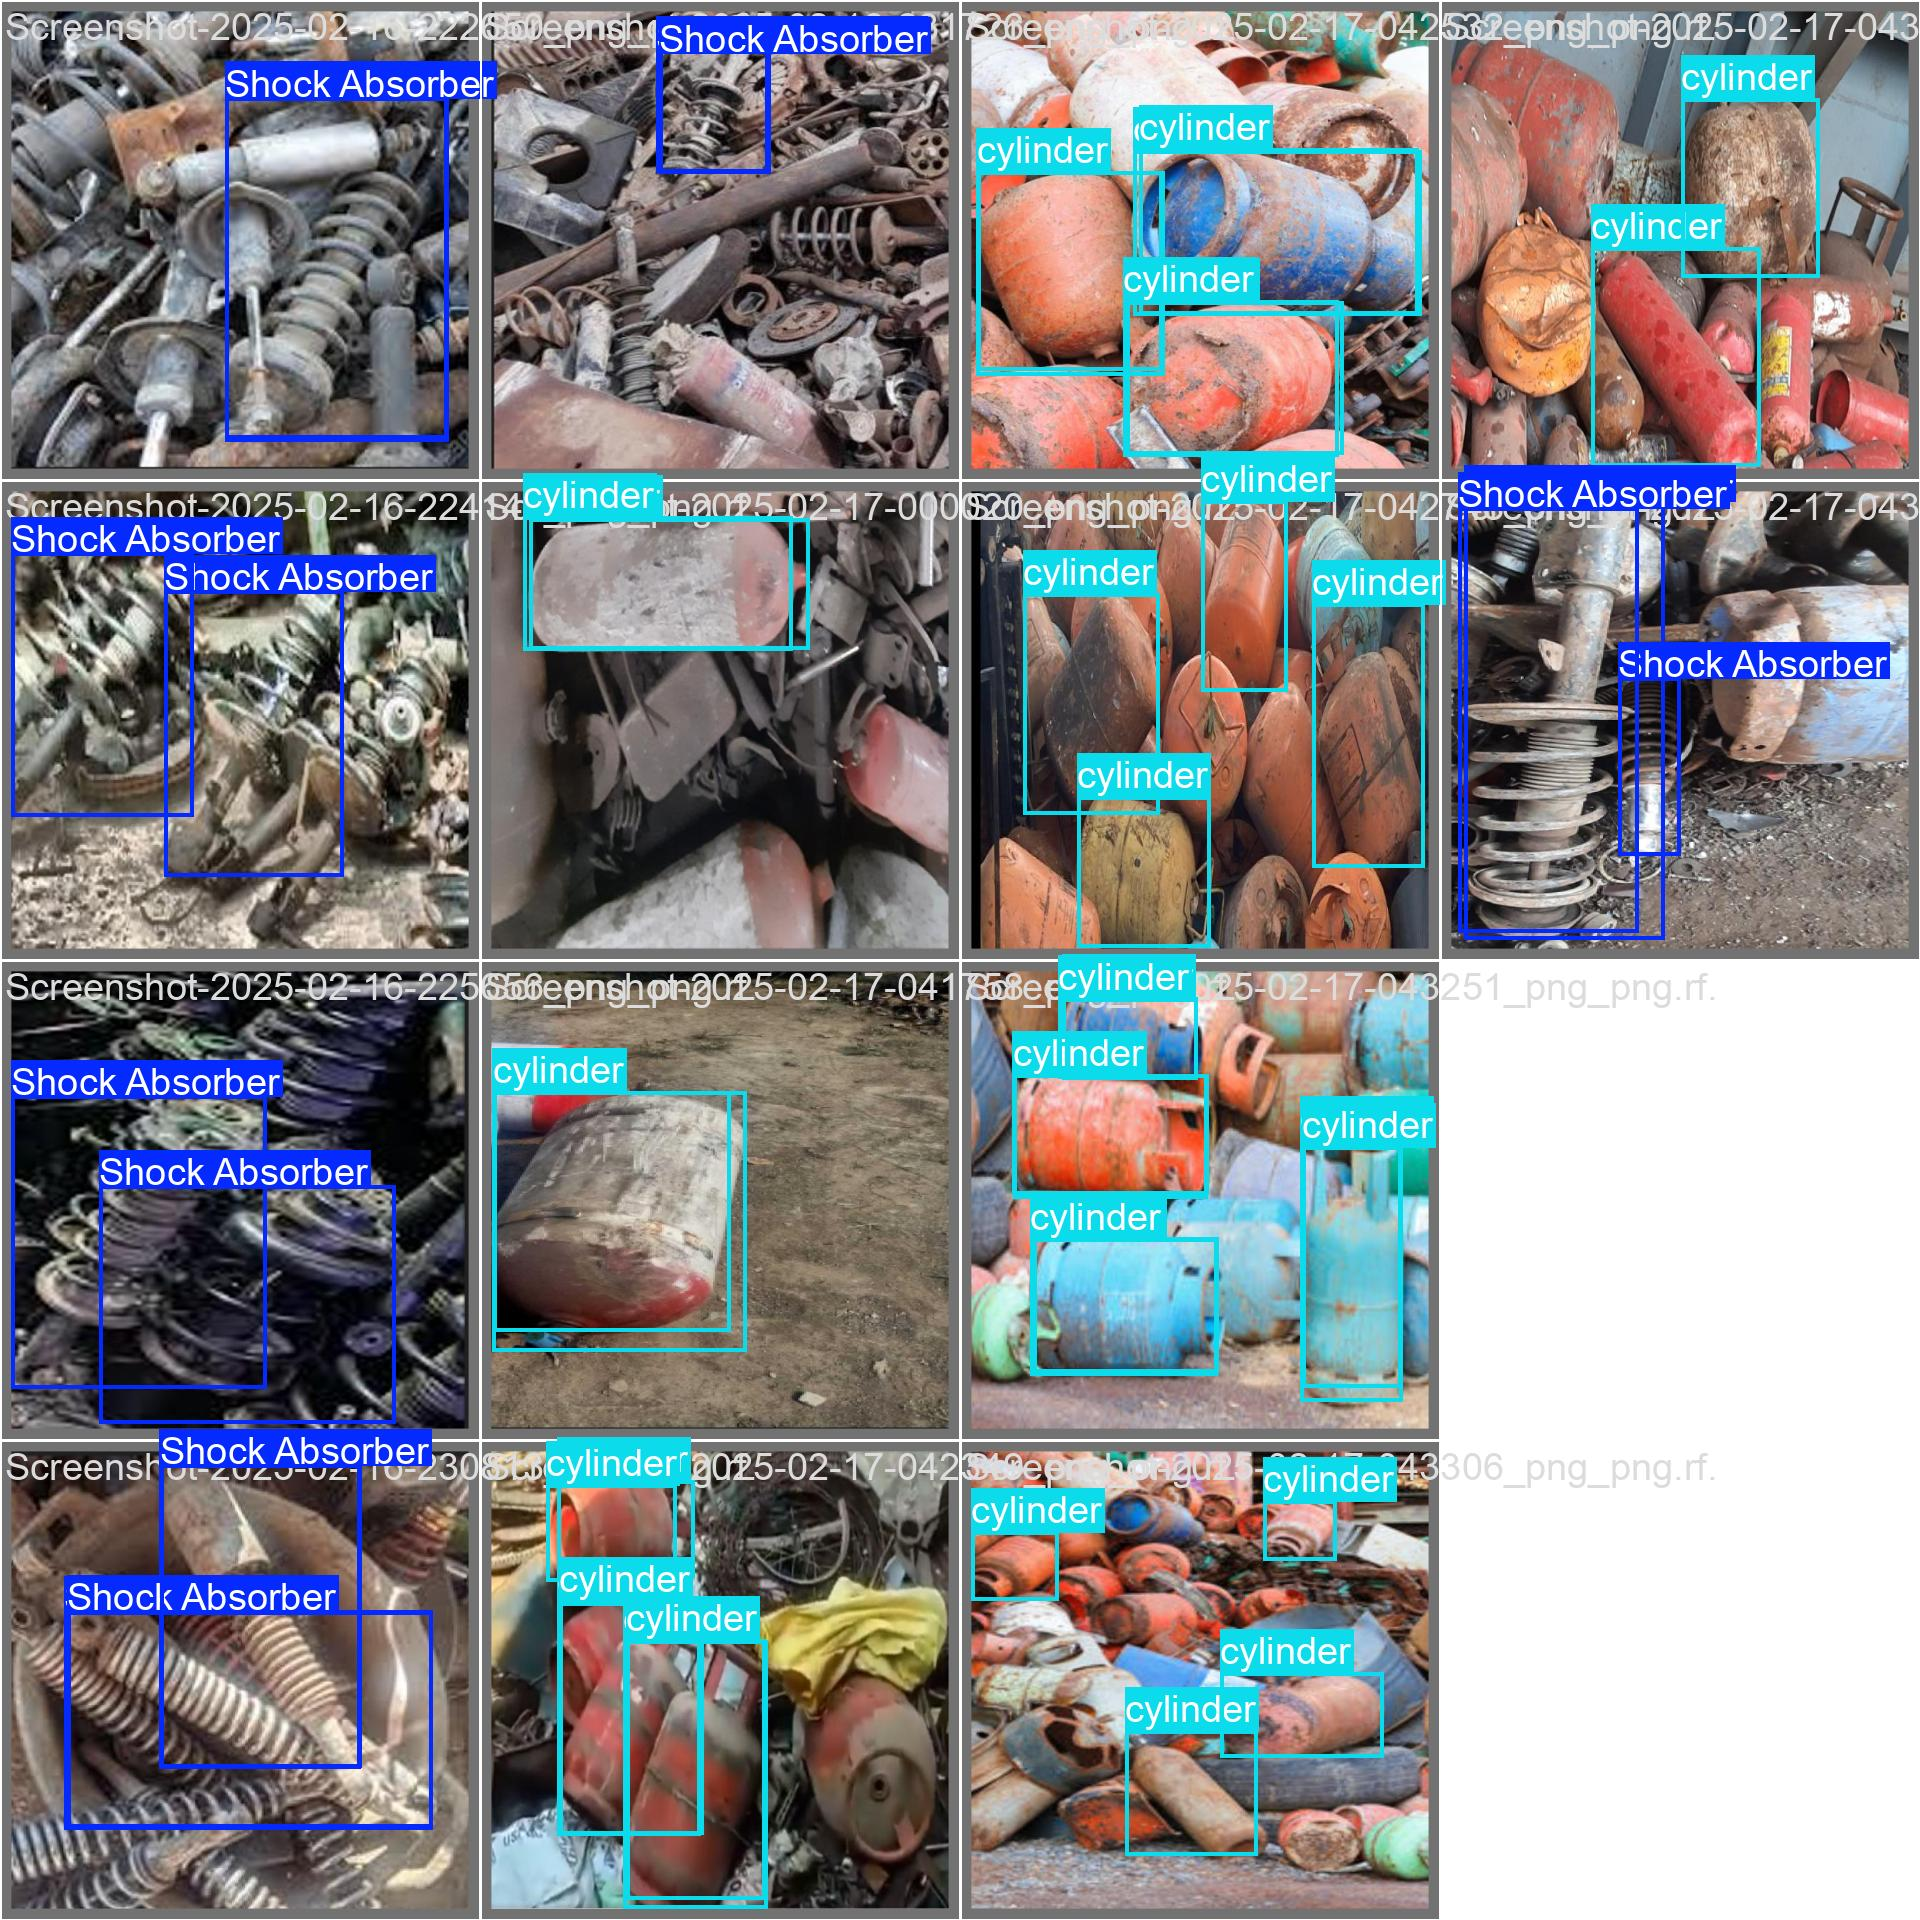


val_batch0_pred.jpg


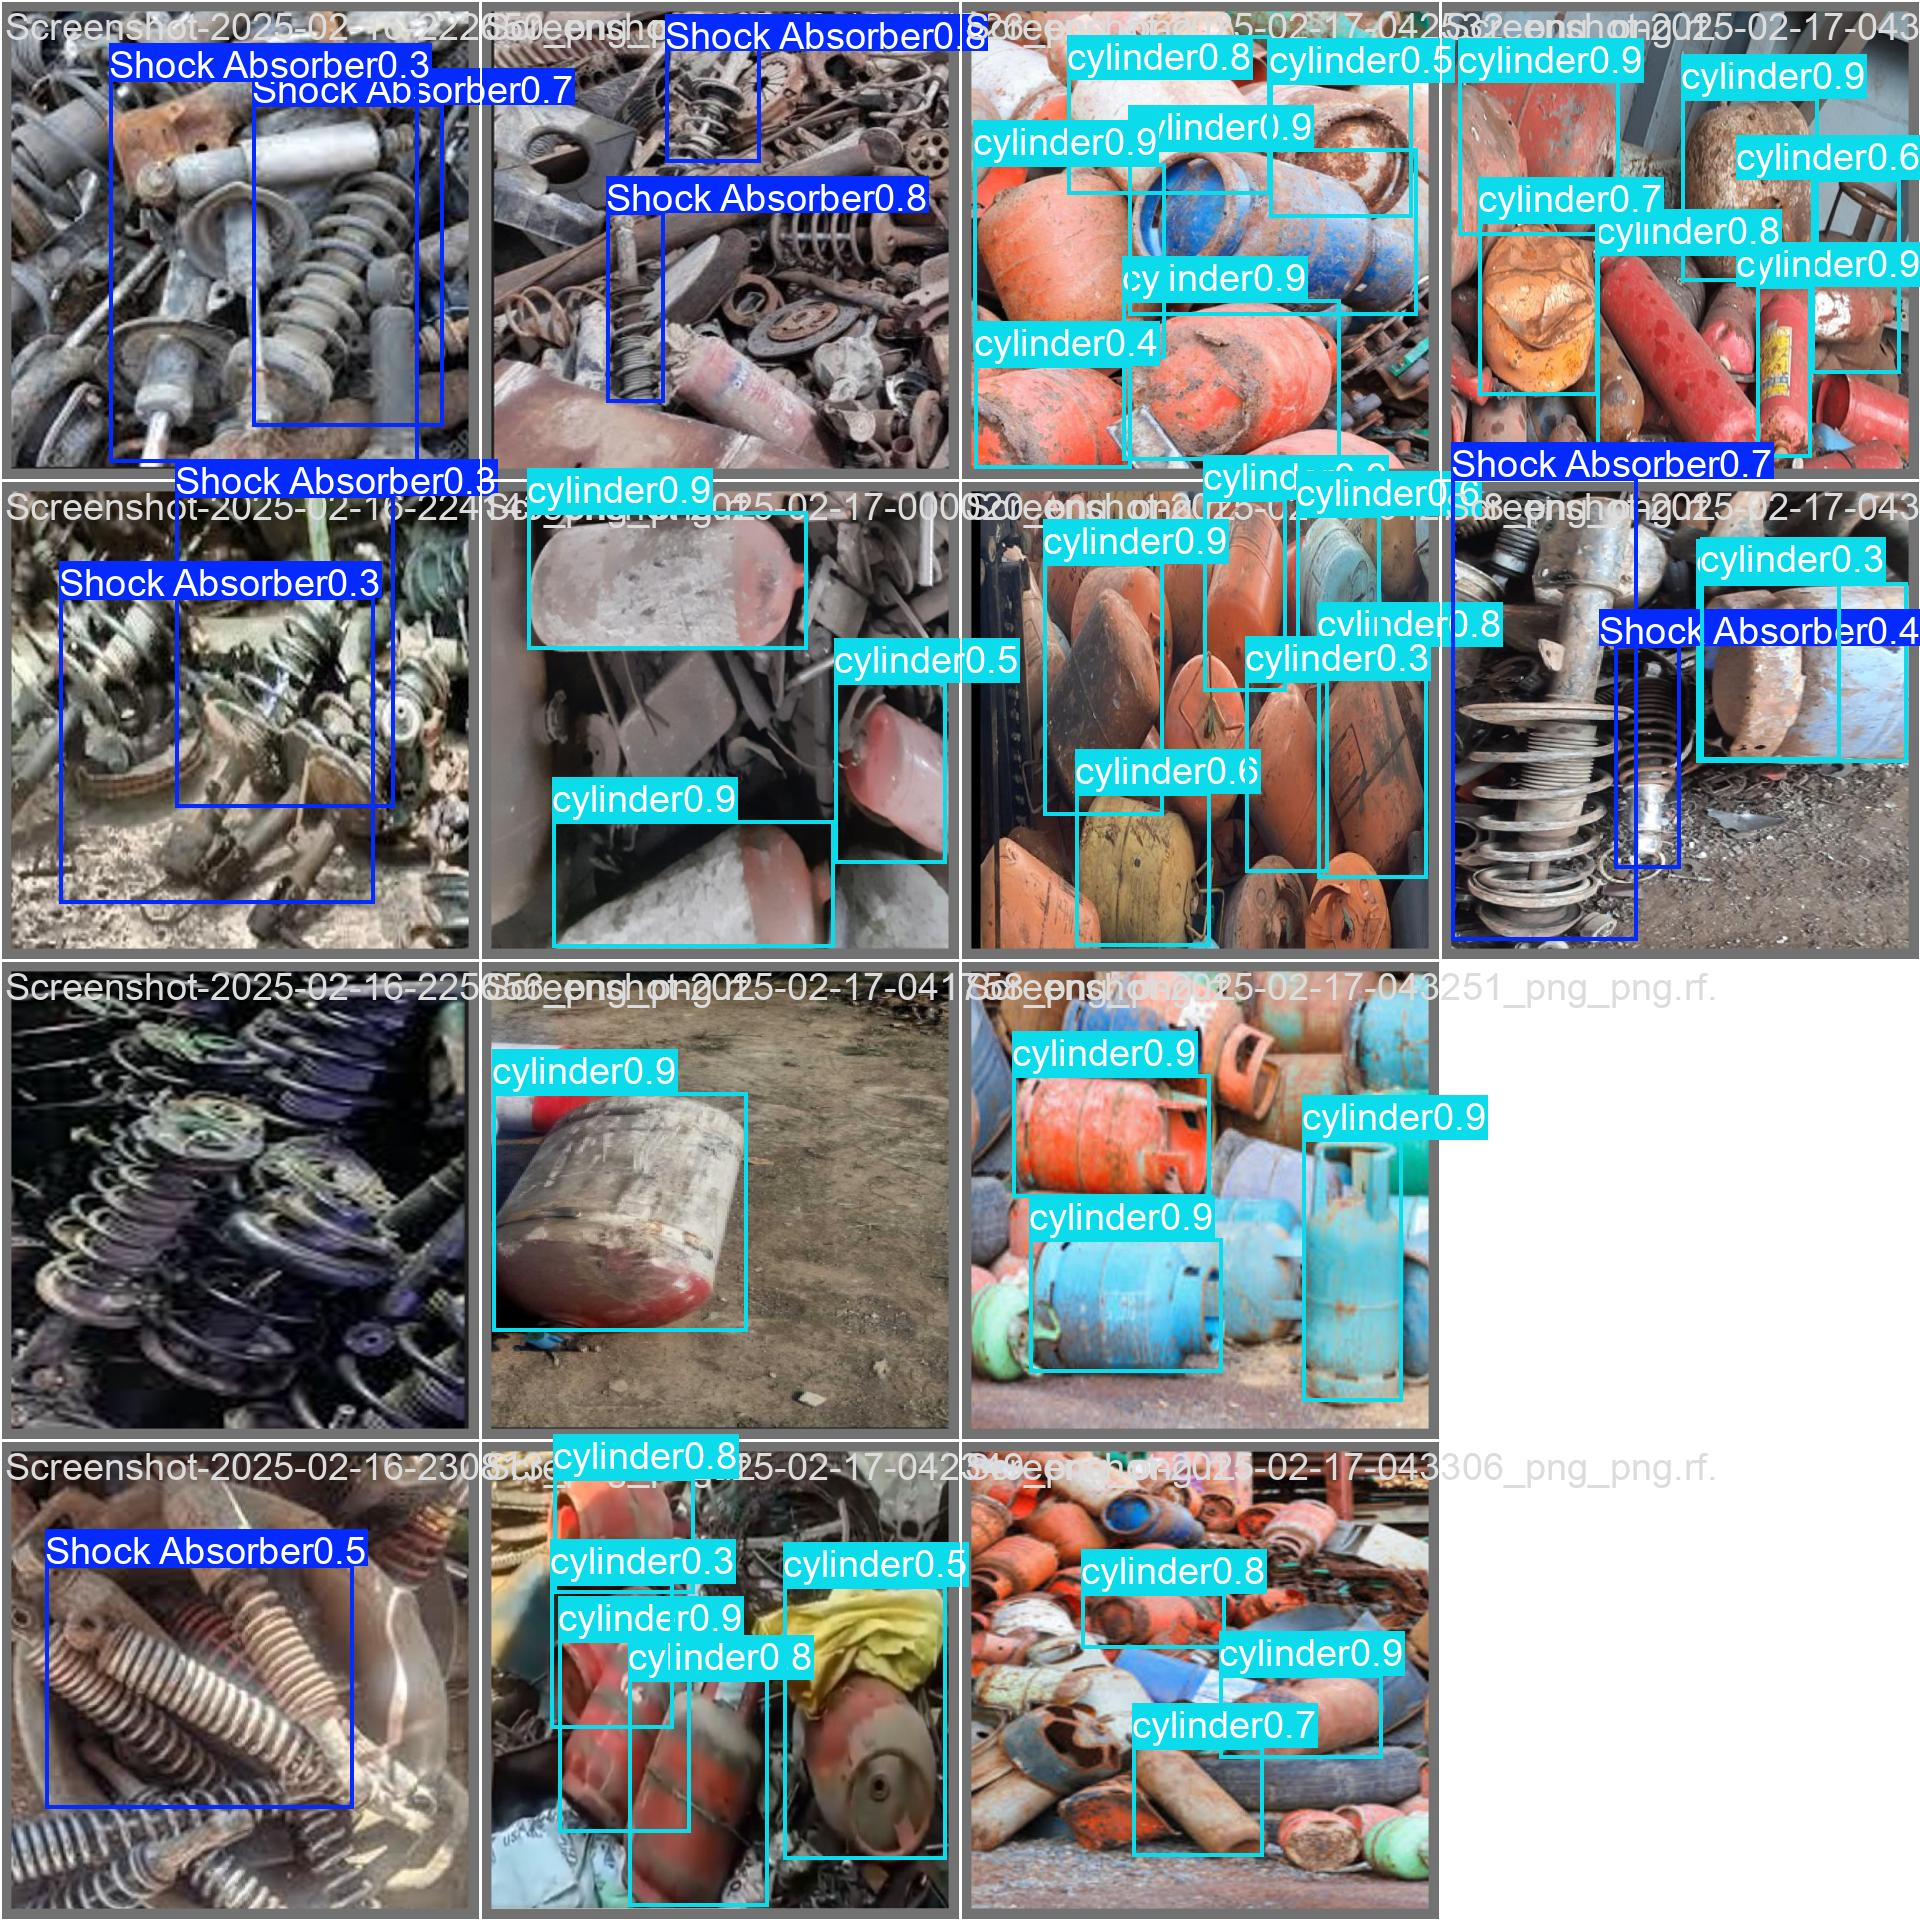

In [26]:

# STEP 8D — VISUAL INSPECTION OF TEST RESULTS

from pathlib import Path
from IPython.display import display, Image

folder = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/"
    "evaluation/yolo26n_original_test_artifacts"
)

files = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
]

for filename in files:
    path = folder / filename
    assert path.is_file(), f"Missing: {filename}"

    print(f"\n{filename}")
    display(Image(filename=str(path), width=850))


1. Understanding the confusion matrix
- Columns (True): What the actual annotated object is.
- Rows (Predicted): What YOLO predicted.
- Diagonal: Correctly classified, matched detections.
- Background column: Predictions that could not be matched to an annotated object (false positives).
- Background row: Annotated objects without a matching prediction (false negatives).

2. What your matrix shows
Actual class	Correct matches	Classified incorrectly	Unmatched predictions
Shock Absorber	14	1 predicted as cylinder	261 predicted as Shock Absorber
Cylinder	30	3 predicted as Shock Absorber	265 predicted as cylinder

The last column counts unmatched predictions, rather than additional ground-truth objects.
Total unmatched predictions shown
526
261 Shock Absorber + 265 cylinder predictions

This is a significant concern, but we must interpret it carefully.

3. Why are there so many unmatched predictions?
Possible explanations include:
1. Incomplete annotations: We previously identified visible objects that were not annotated. The model may detect some of these, which would be counted as false positives.
2. Low confidence threshold: Ultralytics confusion-matrix generation can include low-confidence predictions, producing many more detections than you would see with a typical inference threshold.
3. Genuine false positives: The model may incorrectly detect background objects as shock absorbers or cylinders.
We cannot determine which explanation dominates from the confusion matrix alone.

4. What about the normalized matrix?
The normalized matrix shows:
- 93% of matched/predicted outcomes for actual Shock Absorbers are classified correctly, with approximately 7% classified as Cylinders.
- 88% for actual Cylinders are classified correctly, approximately 9% classified as Shock Absorbers, and 3% are missed in this matrix.
Important: These percentages are normalized by the annotated class columns. They should not be confused with the precision and recall reported by the standard YOLO evaluation, because the confusion matrix can use different confidence and matching settings.

Step 9 — Verify Original vs Balanced Performance

In [27]:

import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/HazWaste_YOLO_Project/experiments"
)

for experiment in ["yolo26n_original", "yolo26n_balanced"]:
    history = pd.read_csv(base / experiment / "results.csv")
    history.columns = history.columns.str.strip()

    best = history.loc[
        history["metrics/mAP50-95(B)"].idxmax()
    ]

    print(f"\n{experiment}")
    print("Best epoch:", int(best["epoch"]))
    print("Precision:", round(best["metrics/precision(B)"], 4))
    print("Recall:", round(best["metrics/recall(B)"], 4))
    print("mAP50:", round(best["metrics/mAP50(B)"], 4))
    print("mAP50-95:", round(best["metrics/mAP50-95(B)"], 4))



yolo26n_original
Best epoch: 48
Precision: 0.5754
Recall: 0.4768
mAP50: 0.5237
mAP50-95: 0.3534

yolo26n_balanced
Best epoch: 50
Precision: 0.7562
Recall: 0.4325
mAP50: 0.4918
mAP50-95: 0.3522
